# SMS Spam Detection
Steps: 1. Data cleaning  2. EDA  3. Text preprocessing  4. Model building  5. Evaluation  6. Improvement  7. Save model

**Changes from the earlier version:** all imports are at the top, the data is split *before* TF-IDF is fitted (no leakage), the split is stratified, recall and F1 are reported, and the improvement section really re-trains the models each time.

Run the cells **top to bottom, once**.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import string
import pickle
import nltk
from collections import Counter
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from wordcloud import WordCloud
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
 

[nltk_data] Downloading package punkt to C:\Users\Shruti
[nltk_data]     Rawat\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Shruti
[nltk_data]     Rawat\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Shruti
[nltk_data]     Rawat\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## 1. Data Cleaning

In [4]:
df = pd.read_csv('spam.csv', encoding='latin-1')
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
1256,ham,"Not yet chikku..going to room nw, i'm in bus..",NaN,NaN,NaN
2740,ham,Nothing. Can...,NaN,NaN,NaN
3660,ham,Well then you have a great weekend!,NaN,NaN,NaN
285,ham,"K, I might come by tonight then if my class le...",NaN,NaN,NaN
5033,ham,I want to go to perumbavoor,NaN,NaN,NaN


In [5]:
df.shape

(5572, 5)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [7]:
# drop last 3 cols (almost empty)
df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'], inplace=True)

In [8]:
# renaming the cols
df.rename(columns={'v1':'target','v2':'text'}, inplace=True)
df.sample(5)

,target,text
3324,ham,Nope... Juz off from work...
3735,ham,Hows the street where the end of library walk is?
3938,ham,Y Ì_ wan to go there? C doctor?
1860,ham,"It could work, we'll reach a consensus at the ..."
2732,ham,How dare you stupid. I wont tell anything to y...


In [9]:
# ham -> 0, spam -> 1
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
df['target'] = encoder.fit_transform(df['target'])
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [10]:
# missing values
df.isnull().sum()

target    0
text      0
dtype: int64

In [11]:
# duplicate values
df.duplicated().sum()

403

In [12]:
# remove duplicates
df = df.drop_duplicates(keep='first')
print(df.duplicated().sum())
print(df.shape)

0
(5169, 2)


## 2. EDA

In [14]:
df['target'].value_counts()

target
0    4516
1     653
Name: count, dtype: int64

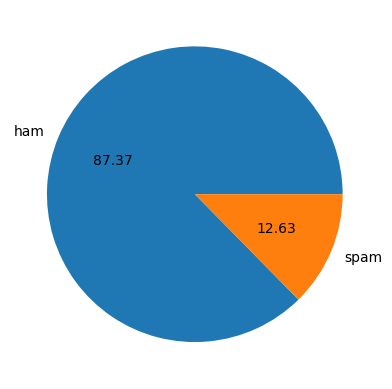

In [15]:
plt.pie(df['target'].value_counts(), labels=['ham','spam'], autopct='%0.2f')
plt.show()
# Data is imbalanced: far more ham than spam

In [16]:
df['num_characters'] = df['text'].apply(len)
df['num_words'] = df['text'].apply(lambda x: len(nltk.word_tokenize(x)))
df['num_sentences'] = df['text'].apply(lambda x: len(nltk.sent_tokenize(x)))
df.head()

,target,text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [17]:
# all messages
df[['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [18]:
# ham
df[df['target'] == 0][['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [19]:
# spam
df[df['target'] == 1][['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


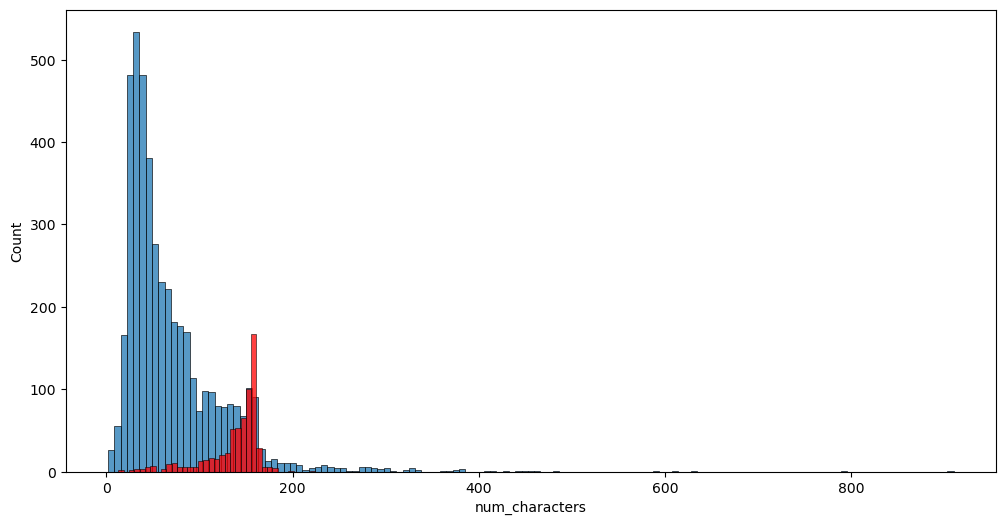

In [20]:
plt.figure(figsize=(12,6))
sns.histplot(df[df['target'] == 0]['num_characters'])
sns.histplot(df[df['target'] == 1]['num_characters'], color='red')
plt.show()

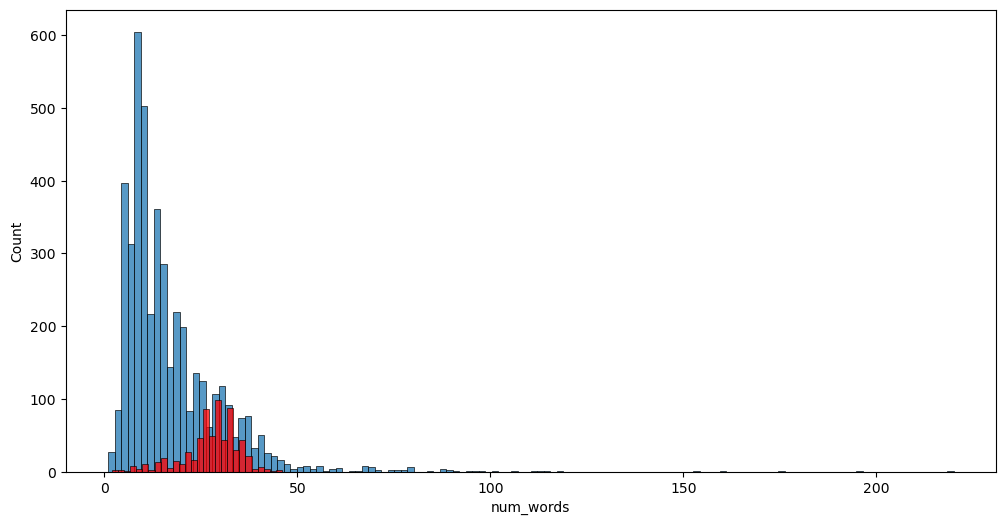

In [21]:
plt.figure(figsize=(12,6))
sns.histplot(df[df['target'] == 0]['num_words'])
sns.histplot(df[df['target'] == 1]['num_words'], color='red')
plt.show()

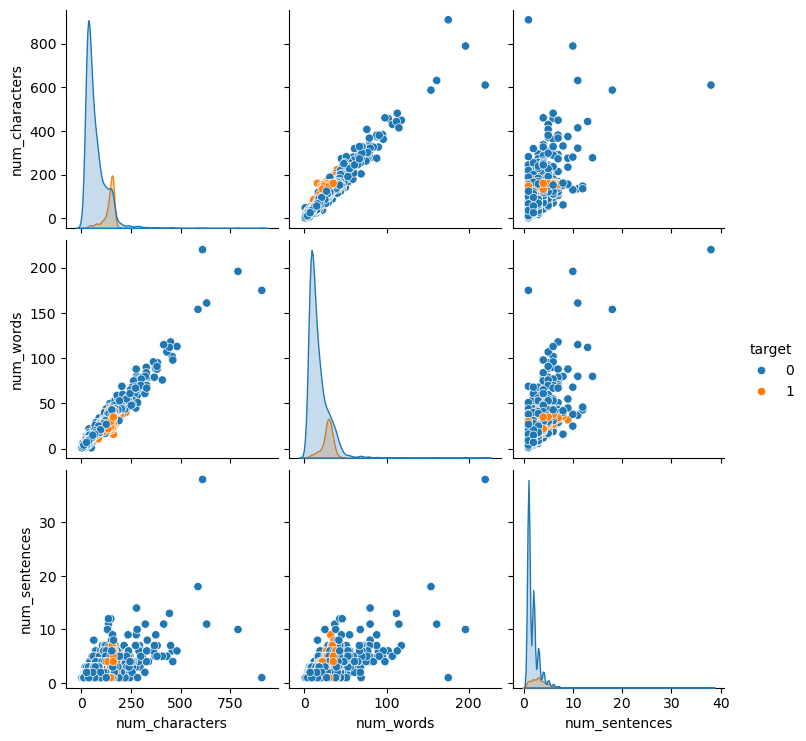

In [22]:
sns.pairplot(df, hue='target')
plt.show()

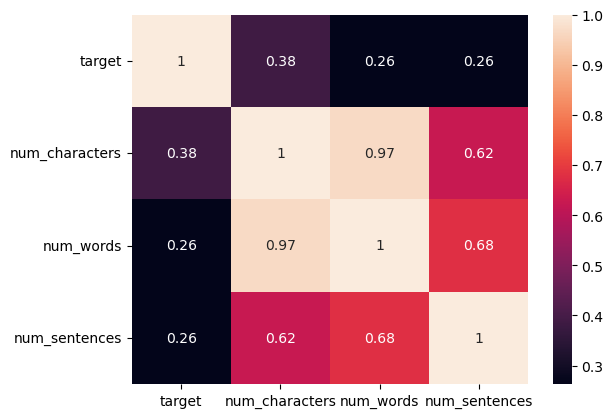

In [23]:
sns.heatmap(df[['target','num_characters','num_words','num_sentences']].corr(), annot=True)
plt.show()

## 3. Text Preprocessing
- Lower case
- Tokenization
- Removing special characters
- Removing stop words and punctuation
- Stemming

In [25]:
ps = PorterStemmer()
stop_words = set(stopwords.words('english'))   # made once, so it is fast

def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)

    y = []
    for i in text:
        if i.isalnum():
            y.append(i)

    text = y[:]
    y.clear()

    for i in text:
        if i not in stop_words and i not in string.punctuation:
            y.append(i)

    text = y[:]
    y.clear()

    for i in text:
        y.append(ps.stem(i))

    return " ".join(y)

In [26]:
# quick test
print(df['text'].iloc[10])
print(transform_text(df['text'].iloc[10]))

I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today.
gon na home soon want talk stuff anymor tonight k cri enough today


In [27]:
df['transformed_text'] = df['text'].apply(transform_text)
df.head()

,target,text,num_characters,num_words,num_sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


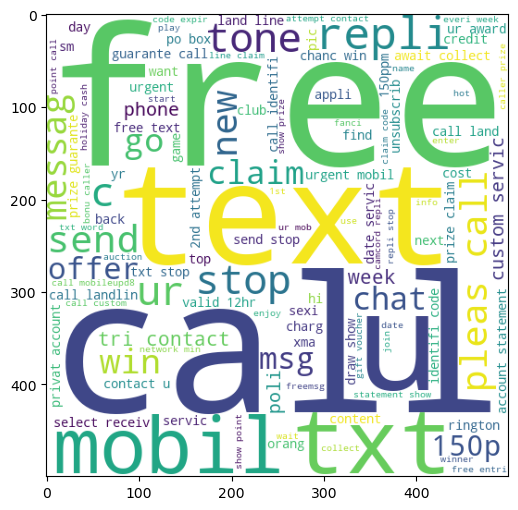

In [28]:
wc = WordCloud(width=500, height=500, min_font_size=10, background_color='white')

spam_wc = wc.generate(df[df['target'] == 1]['transformed_text'].str.cat(sep=" "))
plt.figure(figsize=(15,6))
plt.imshow(spam_wc)
plt.show()

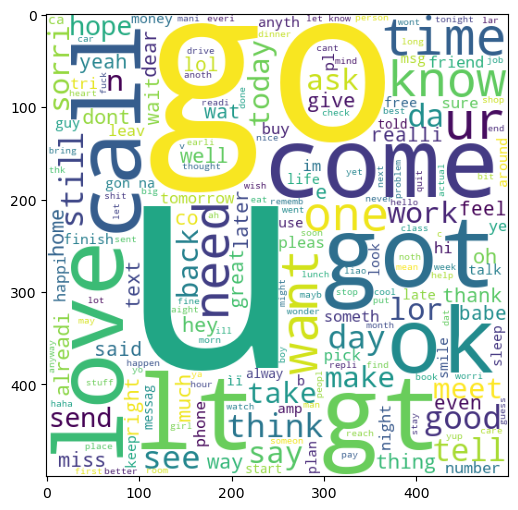

In [29]:
ham_wc = wc.generate(df[df['target'] == 0]['transformed_text'].str.cat(sep=" "))
plt.figure(figsize=(15,6))
plt.imshow(ham_wc)
plt.show()

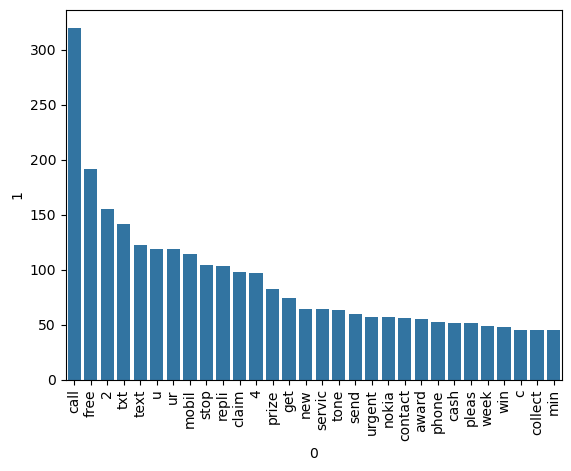

In [30]:
# most common words in spam
spam_corpus = []
for msg in df[df['target'] == 1]['transformed_text'].tolist():
    for word in msg.split():
        spam_corpus.append(word)

top_spam = pd.DataFrame(Counter(spam_corpus).most_common(30))
sns.barplot(x=top_spam[0], y=top_spam[1])
plt.xticks(rotation='vertical')
plt.show()

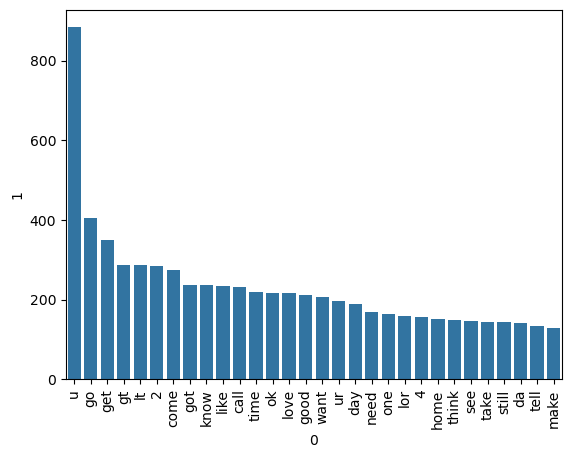

In [31]:
# most common words in ham
ham_corpus = []
for msg in df[df['target'] == 0]['transformed_text'].tolist():
    for word in msg.split():
        ham_corpus.append(word)

top_ham = pd.DataFrame(Counter(ham_corpus).most_common(30))
sns.barplot(x=top_ham[0], y=top_ham[1])
plt.xticks(rotation='vertical')
plt.show()

## 4. Model Building
**Split first, then fit TF-IDF only on the training text.** (Fitting on all the data lets the test set leak into training.)

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['transformed_text'], df['target'].values,
    test_size=0.2, random_state=2, stratify=df['target'].values)

tfidf = TfidfVectorizer(max_features=3000)
X_train = tfidf.fit_transform(X_train_text).toarray()   # fit on train only
X_test = tfidf.transform(X_test_text).toarray()         # only transform on test

print(X_train.shape, X_test.shape)

(4135, 3000) (1034, 3000)


In [34]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

for name, model in [('GaussianNB', GaussianNB()), ('MultinomialNB', MultinomialNB()), ('BernoulliNB', BernoulliNB())]:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(name)
    print('Accuracy :', accuracy_score(y_test, y_pred))
    print('Precision:', precision_score(y_test, y_pred))
    print('Recall   :', recall_score(y_test, y_pred))
    print(confusion_matrix(y_test, y_pred))
    print()

GaussianNB
Accuracy : 0.8491295938104448
Precision: 0.4524714828897338
Recall   : 0.9083969465648855
[[759 144]
 [ 12 119]]

MultinomialNB
Accuracy : 0.9787234042553191
Precision: 1.0
Recall   : 0.8320610687022901
[[903   0]
 [ 22 109]]

BernoulliNB
Accuracy : 0.988394584139265
Precision: 0.9917355371900827
Recall   : 0.916030534351145
[[902   1]
 [ 11 120]]



## 5. Evaluation - compare many models
For spam, **precision** (don't mark real messages as spam) matters, but also **recall** (catch the spam). So we look at both.

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

def get_models():
    return {
        'SVC': SVC(kernel='sigmoid', gamma=1.0),
        'KN': KNeighborsClassifier(),
        'NB': MultinomialNB(),
        'DT': DecisionTreeClassifier(max_depth=5),
        'LR': LogisticRegression(solver='liblinear', penalty='l1'),
        'RF': RandomForestClassifier(n_estimators=50, random_state=2),
        'AdaBoost': AdaBoostClassifier(n_estimators=50, random_state=2, algorithm='SAMME'),
        'BgC': BaggingClassifier(n_estimators=50, random_state=2),
        'ETC': ExtraTreesClassifier(n_estimators=50, random_state=2),
        'GBDT': GradientBoostingClassifier(n_estimators=50, random_state=2),
        'xgb': XGBClassifier(n_estimators=50, random_state=2),
    }

def train_classifier(clf, X_train, y_train, X_test, y_test):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred)
    return accuracy, precision, recall

In [37]:
rows = []
for name, clf in get_models().items():
    acc, prec, rec = train_classifier(clf, X_train, y_train, X_test, y_test)
    rows.append({'Algorithm': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec})

performance_df = pd.DataFrame(rows).sort_values('Precision', ascending=False)
performance_df

,Algorithm,Accuracy,Precision,Recall
1,KN,0.915861,1.000000,0.335878
2,NB,0.978723,1.000000,0.832061
5,RF,0.985493,0.991525,0.893130
8,ETC,0.984526,0.983193,0.893130
9,GBDT,0.957447,0.967742,0.687023
0,SVC,0.985493,0.960317,0.923664
10,xgb,0.970986,0.939130,0.824427
4,LR,0.965184,0.935780,0.778626
7,BgC,0.964217,0.879032,0.832061
3,DT,0.934236,0.794393,0.648855


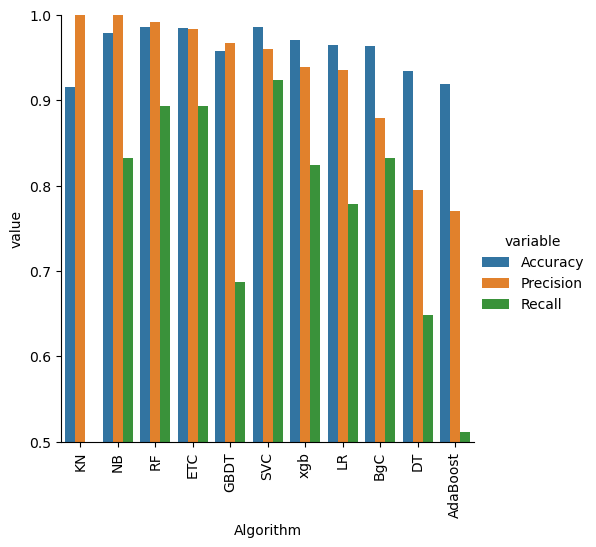

In [38]:
performance_df1 = pd.melt(performance_df, id_vars='Algorithm')
sns.catplot(x='Algorithm', y='value', hue='variable', data=performance_df1, kind='bar', height=5)
plt.ylim(0.5, 1.0)
plt.xticks(rotation='vertical')
plt.show()

## 6. Improvement
**Idea 1:** change `max_features` of TF-IDF (1000, 2000, 3000). Each time the vectorizer and all models are really re-trained.

In [40]:
results = {}
for mf in [1000, 2000, 3000]:
    tf = TfidfVectorizer(max_features=mf)
    Xtr = tf.fit_transform(X_train_text).toarray()
    Xte = tf.transform(X_test_text).toarray()
    rows = []
    for name, clf in get_models().items():
        acc, prec, rec = train_classifier(clf, Xtr, y_train, Xte, y_test)
        rows.append({'Algorithm': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec})
    results[mf] = pd.DataFrame(rows).set_index('Algorithm')

# precision for each max_features, side by side
pd.DataFrame({f'Precision_{mf}': r['Precision'] for mf, r in results.items()})

,Precision_1000,Precision_2000,Precision_3000
Algorithm,,,
SVC,0.967213,0.967480,0.960317
KN,1.000000,1.000000,1.000000
NB,0.983051,1.000000,1.000000
DT,0.843750,0.807692,0.794393
LR,0.931034,0.930435,0.935780
RF,1.000000,0.991304,0.991525
AdaBoost,0.764045,0.734694,0.770115
BgC,0.870229,0.869231,0.879032
ETC,0.960317,0.975610,0.983193


In [41]:
# recall for each max_features, side by side
pd.DataFrame({f'Recall_{mf}': r['Recall'] for mf, r in results.items()})

,Recall_1000,Recall_2000,Recall_3000
Algorithm,,,
SVC,0.900763,0.908397,0.923664
KN,0.389313,0.366412,0.335878
NB,0.885496,0.847328,0.832061
DT,0.618321,0.641221,0.648855
LR,0.824427,0.816794,0.778626
RF,0.870229,0.870229,0.893130
AdaBoost,0.519084,0.549618,0.511450
BgC,0.870229,0.862595,0.832061
ETC,0.923664,0.916031,0.893130


**Idea 2:** combine the best models - Voting and Stacking (using the 3000-feature data from section 4).

In [43]:
from sklearn.ensemble import VotingClassifier, StackingClassifier

svc = SVC(kernel='sigmoid', gamma=1.0, probability=True)
mnb = MultinomialNB()
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)

voting = VotingClassifier(estimators=[('svm', svc), ('nb', mnb), ('et', etc)], voting='soft')
voting.fit(X_train, y_train)
y_pred = voting.predict(X_test)
print('Voting   - Accuracy:', accuracy_score(y_test, y_pred), '| Precision:', precision_score(y_test, y_pred), '| Recall:', recall_score(y_test, y_pred))

Voting   - Accuracy: 0.9893617021276596 | Precision: 0.9918032786885246 | Recall: 0.9236641221374046


In [44]:
estimators = [('svm', svc), ('nb', mnb), ('et', etc)]
stacking = StackingClassifier(estimators=estimators, final_estimator=RandomForestClassifier(random_state=2))
stacking.fit(X_train, y_train)
y_pred = stacking.predict(X_test)
print('Stacking - Accuracy:', accuracy_score(y_test, y_pred), '| Precision:', precision_score(y_test, y_pred), '| Recall:', recall_score(y_test, y_pred))

Stacking - Accuracy: 0.9903288201160542 | Precision: 0.9763779527559056 | Recall: 0.9465648854961832


## 7. Final model
Pick the model you want to keep and look at its full report. Change `final_model` below if you prefer another (e.g. `mnb` for the simple Naive Bayes).

In [46]:
from sklearn.metrics import classification_report

final_model = voting          # <- change this if you want a different model
y_pred = final_model.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['ham', 'spam']))

[[902   1]
 [ 10 121]]
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.99      0.92      0.96       131

    accuracy                           0.99      1034
   macro avg       0.99      0.96      0.98      1034
weighted avg       0.99      0.99      0.99      1034



In [47]:
# NOTE: mnb is already trained (it was fitted inside the earlier cells).
# If you chose voting, it is trained too.
pickle.dump(tfidf, open('vectorizer.pkl', 'wb'))
pickle.dump(final_model, open('model.pkl', 'wb'))

In [48]:
# test the saved files on a new message
tfidf_loaded = pickle.load(open('vectorizer.pkl', 'rb'))
model_loaded = pickle.load(open('model.pkl', 'rb'))

msg = "Congratulations! You have won a free prize. Call now to claim."
vec = tfidf_loaded.transform([transform_text(msg)]).toarray()
print('SPAM' if model_loaded.predict(vec)[0] == 1 else 'NOT SPAM')

SPAM
